# Day 1 — Python and Pandas Basics

In [ ]:
import pandas as pd
print("Python & Pandas are Working")

Python & Pandas are Working


In [ ]:
data = {
    "Vehicle Model": ["A1","B1","C1"],
    "UnitSold": [12, 10, 8],
    "Revenue": [360000,300000, 240000],
}

In [ ]:
data

{'Vehicle Model': ['A1', 'B1', 'C1'],
 'UnitSold': [12, 10, 8],
 'Revenue': [360000, 300000, 240000]}

In [ ]:
df = pd.DataFrame(data)

In [ ]:
df

,Vehicle Model,UnitSold,Revenue
0,A1,12,360000
1,B1,10,300000
2,C1,8,240000


In [ ]:
df.shape

(3, 3)

In [ ]:
df.columns

Index(['Vehicle Model', 'UnitSold', 'Revenue'], dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Vehicle Model  3 non-null      object
 1   UnitSold       3 non-null      int64 
 2   Revenue        3 non-null      int64 
dtypes: int64(2), object(1)
memory usage: 204.0+ bytes


In [ ]:
df.describe()

,UnitSold,Revenue
count,3.0,3.0
mean,10.0,300000.0
std,2.0,60000.0
min,8.0,240000.0
25%,9.0,270000.0
50%,10.0,300000.0
75%,11.0,330000.0
max,12.0,360000.0


In [ ]:
df["Revenue"]

,Revenue
0,360000
1,300000
2,240000


In [ ]:
df["Revenue"].sum()

np.int64(900000)

In [ ]:
df["UnitSold"].sum()

np.int64(30)

In [ ]:
df["Revenue"].mean()

np.float64(300000.0)

In [ ]:
df["Revenue"].max()

360000

In [ ]:
df["Revenue"].idxmax()

0

In [ ]:
df.loc[0, "Vehicle Model"]

'A1'

In [ ]:
df.sort_values("Revenue", ascending=False)

,Vehicle Model,UnitSold,Revenue
0,A1,12,360000
1,B1,10,300000
2,C1,8,240000


In [ ]:
df["Revenue"] > 300000

,Revenue
0,True
1,False
2,False


In [ ]:
df[df["Revenue"] > 300000]

,Vehicle Model,UnitSold,Revenue
0,A1,12,360000


In [ ]:
df["Revenue Per Unit"] = df["Revenue"] / df["UnitSold"]

In [ ]:
df

,Vehicle Model,UnitSold,Revenue,Revenue Per Unit
0,A1,12,360000,30000.0
1,B1,10,300000,30000.0
2,C1,8,240000,30000.0


In [ ]:
df[["Vehicle Model", "Revenue Per Unit"]]

,Vehicle Model,Revenue Per Unit
0,A1,30000.0
1,B1,30000.0
2,C1,30000.0


All three vehicle models generate the same revenue per unit at 30000. Therefore the difference in total revenue is caused by unit sold not by the revenue earned per unit.

# Day 2 — Grouping Data with Pandas

In [ ]:
df.groupby("Vehicle Model")["Revenue"].sum()

,Revenue
Vehicle Model,
A1,360000
B1,300000
C1,240000


In [ ]:
data2 = {
    "Vehicle Model": ["A1","A1","B1","B1","C1","C1"],
    "Region": ["Delhi","Noida","Delhi","Gurugram","Sonipat","Noida"],
    "UnitSold": [12, 18, 10, 15, 8, 14],
    "Revenue": [360000,540000,300000,450000,240000,420000],
}

In [ ]:
df2= pd.DataFrame(data2)

In [ ]:
df2

,Vehicle Model,Region,UnitSold,Revenue
0,A1,Delhi,12,360000
1,A1,Noida,18,540000
2,B1,Delhi,10,300000
3,B1,Gurugram,15,450000
4,C1,Sonipat,8,240000
5,C1,Noida,14,420000


In [ ]:
df2.groupby(["Vehicle Model"])["Revenue"].sum()

,Revenue
Vehicle Model,
A1,900000
B1,750000
C1,660000


In [ ]:
df2.groupby(["Vehicle Model"])["UnitSold"].sum()

,UnitSold
Vehicle Model,
A1,30
B1,25
C1,22


In [ ]:
df2.groupby(["Region"])["Revenue"].sum()

,Revenue
Region,
Delhi,660000
Gurugram,450000
Noida,960000
Sonipat,240000


Noida generated the highest revenue at 960,000, while Sonipat generated the lowest revenue at 240,000. The business should investigate the reasons for Sonipat’s lower performance before deciding on promotional or dealer-support actions.

# Day 3 — Sorting and Visualizing Data

In [ ]:
regional_revenue = df2.groupby(["Region"])["Revenue"].sum()
regional_revenue.sort_values(ascending=False)

,Revenue
Region,
Noida,960000
Delhi,660000
Gurugram,450000
Sonipat,240000


In [ ]:
regional_revenue_df = regional_revenue.sort_values(ascending=False).reset_index()

In [ ]:
regional_revenue_df

,Region,Revenue
0,Noida,960000
1,Delhi,660000
2,Gurugram,450000
3,Sonipat,240000


In [ ]:
import matplotlib.pyplot as plt

In [ ]:
regional_revenue_df["Revenue_Lakhs"] = regional_revenue_df["Revenue"] / 100000

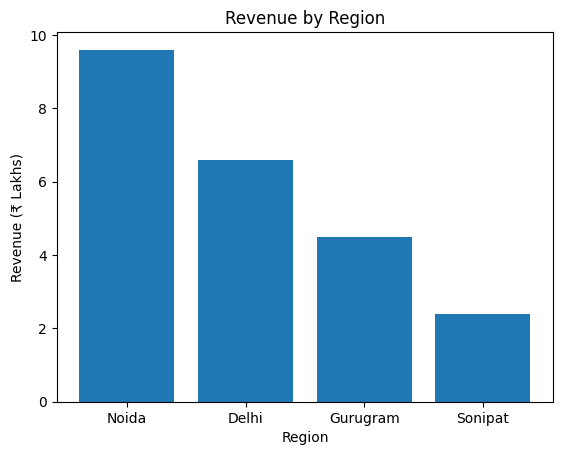

In [ ]:
plt.bar(
    regional_revenue_df["Region"],
    regional_revenue_df["Revenue_Lakhs"]
    )
plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue (₹ Lakhs)")
plt.show()


Noida has the highest revenue, while Sonipat has the lowest revenue. The business should investigate the reasons for Sonipat’s lower sales, including product demand, product availability, dealer performance, pricing, and promotional activity. After identifying the main cause, the company can take targeted actions such as improving product availability, supporting dealers, or running suitable promotional campaigns in the region.

# Day 4 — Data Cleaning and Missing Values

### Part 1 — Missing Values and Duplicate Records

In [ ]:
data3= {
    "Employee": ["Raj", "Arjan", "Krishna", "Devraj", "Ankit"],
    "Department": ["Sales", "HR", "Production", "Dispatch", "Procurement"],
    "Salary": [50000, 65000, 55000, None, 42000],
    "City": ["Delhi", "Noida", None, "Gurugram", "Sonipat"],
}

In [ ]:
df3 = pd.DataFrame(data3)

In [ ]:
df3

,Employee,Department,Salary,City
0,Raj,Sales,50000.0,Delhi
1,Arjan,HR,65000.0,Noida
2,Krishna,Production,55000.0,None
3,Devraj,Dispatch,NaN,Gurugram
4,Ankit,Procurement,42000.0,Sonipat


In [ ]:
df3.isna().sum()

,0
Employee,0
Department,0
Salary,1
City,1


In [ ]:
df3[df3.isna().any(axis=1)]

,Employee,Department,Salary,City
2,Krishna,Production,55000.0,None
3,Devraj,Dispatch,NaN,Gurugram


In [ ]:
df3["City"] = df3["City"].fillna("Unknown")

In [ ]:
df3

,Employee,Department,Salary,City
0,Raj,Sales,50000.0,Delhi
1,Arjan,HR,65000.0,Noida
2,Krishna,Production,55000.0,Unknown
3,Devraj,Dispatch,NaN,Gurugram
4,Ankit,Procurement,42000.0,Sonipat


In [ ]:
df3['Salary'].median()

52500.0

In [ ]:
df3["Salary"] = df3["Salary"].fillna(df3['Salary'].median())

In [ ]:
df3

,Employee,Department,Salary,City
0,Raj,Sales,50000.0,Delhi
1,Arjan,HR,65000.0,Noida
2,Krishna,Production,55000.0,Unknown
3,Devraj,Dispatch,52500.0,Gurugram
4,Ankit,Procurement,42000.0,Sonipat


In [ ]:
df3.isna().sum()

,0
Employee,0
Department,0
Salary,0
City,0


In [ ]:
df3.duplicated().sum()

np.int64(0)

In [ ]:
df4= pd.concat([df3,df3.iloc[[0]]])

In [ ]:
df4

,Employee,Department,Salary,City
0,Raj,Sales,50000.0,Delhi
1,Arjan,HR,65000.0,Noida
2,Krishna,Production,55000.0,Unknown
3,Devraj,Dispatch,52500.0,Gurugram
4,Ankit,Procurement,42000.0,Sonipat
0,Raj,Sales,50000.0,Delhi


In [ ]:
df4.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
0,True


In [ ]:
df4_clean = df4.drop_duplicates()

In [ ]:
df4_clean

,Employee,Department,Salary,City
0,Raj,Sales,50000.0,Delhi
1,Arjan,HR,65000.0,Noida
2,Krishna,Production,55000.0,Unknown
3,Devraj,Dispatch,52500.0,Gurugram
4,Ankit,Procurement,42000.0,Sonipat


In [ ]:
df4_clean.duplicated().sum()

np.int64(0)

In [ ]:
df4_clean.shape

(5, 4)

### Part 2 — Data Types and Type Conversion

In [ ]:
df4_clean.dtypes

,0
Employee,object
Department,object
Salary,float64
City,object


In [ ]:
from numpy import int64
df4_clean.loc[:,"Salary"] = df4_clean["Salary"].astype(int64)

In [ ]:
df4_clean.dtypes

,0
Employee,object
Department,object
Salary,float64
City,object


In [ ]:
df4_clean = df4_clean.copy()

In [ ]:
df4_clean["Join_Date"] = ["2023-01-15","2023-02-20","2023-03-10","2023-04-05", "2023-05-12"]

In [ ]:
df4_clean

,Employee,Department,Salary,City,Join_Date
0,Raj,Sales,50000.0,Delhi,2023-01-15
1,Arjan,HR,65000.0,Noida,2023-02-20
2,Krishna,Production,55000.0,Unknown,2023-03-10
3,Devraj,Dispatch,52500.0,Gurugram,2023-04-05
4,Ankit,Procurement,42000.0,Sonipat,2023-05-12


In [ ]:
df4_clean.dtypes

,0
Employee,object
Department,object
Salary,float64
City,object
Join_Date,object


In [ ]:
df4_clean["Join_Date"] = pd.to_datetime(df4_clean["Join_Date"])

In [ ]:
df4_clean.dtypes

,0
Employee,object
Department,object
Salary,float64
City,object
Join_Date,datetime64[ns]


Day 4 Reflection
Today I learned how to clean a DataFrame before using it for analysis. I learned the difference between missing values, empty text, and zero values. I practiced finding missing values, replacing a missing city with Unknown, and filling a missing salary with the median.

I also learned how to identify and remove duplicate records. In the second part, I checked data types, converted the Salary column to integer, added a new column, and converted text dates into proper date values using pd.to_datetime().

This session helped me understand that data cleaning is an important step before analysis because missing values, duplicates, and incorrect data types can affect the accuracy of the results.

# Day 5 — Exploratory Data Analysis

In [ ]:
df4_clean

,Employee,Department,Salary,City,Join_Date
0,Raj,Sales,50000.0,Delhi,2023-01-15
1,Arjan,HR,65000.0,Noida,2023-02-20
2,Krishna,Production,55000.0,Unknown,2023-03-10
3,Devraj,Dispatch,52500.0,Gurugram,2023-04-05
4,Ankit,Procurement,42000.0,Sonipat,2023-05-12


In [ ]:
df4_clean.dtypes

,0
Employee,object
Department,object
Salary,float64
City,object
Join_Date,datetime64[ns]


In [ ]:
df4_clean.isna().sum()

,0
Employee,0
Department,0
Salary,0
City,0
Join_Date,0


In [ ]:
df4_clean = df4_clean.copy()
df4_clean["Salary"] = df4_clean["Salary"].astype(int64)

In [ ]:
df4_clean.dtypes

,0
Employee,object
Department,object
Salary,int64
City,object
Join_Date,datetime64[ns]


In [ ]:
df4_clean.describe()

,Salary,Join_Date
count,5.000000,5
mean,52900.000000,2023-03-13 09:36:00
min,42000.000000,2023-01-15 00:00:00
25%,50000.000000,2023-02-20 00:00:00
50%,52500.000000,2023-03-10 00:00:00
75%,55000.000000,2023-04-05 00:00:00
max,65000.000000,2023-05-12 00:00:00
std,8339.664262,NaN


***The average salary is 52,900, while the median salary is 52,500.***

***The highest salary is 65,000 and the lowest salary is 42,000, giving a difference of 13,000.***

***The median salary of 52,500 means that half of the salary values are at or below 52,500 and half are at or above it.***

In [ ]:
df4_clean["Join_Date"].dt.year

,Join_Date
0,2023
1,2023
2,2023
3,2023
4,2023


In [ ]:
df4_clean["Join_Date"].dt.month

,Join_Date
0,1
1,2
2,3
3,4
4,5


In [ ]:
df4_clean["Join_Date"].max()

Timestamp('2023-05-12 00:00:00')

In [ ]:
df4_clean["Join_Date"].min()

Timestamp('2023-01-15 00:00:00')

The data covers a five-month period from January to May 2023. Since all records belong to 2023, the dataset represents only part of one year. It is therefore limited for analyzing a complete annual trend. At least one full year of data would be more suitable for studying seasonal or yearly patterns.

In [ ]:
Highest_Salary_Index = df4_clean["Salary"].idxmax()

In [ ]:
df4_clean.loc[Highest_Salary_Index, ["Employee", "Salary"]]

,1
Employee,Arjan
Salary,65000


## Day 5 Reflection

Today I practiced exploratory data analysis using a cleaned employee DataFrame. I reviewed summary statistics, compared average and median salary, extracted information from dates, and identified the highest-paid employee.

I also learned that the data covers only five months of 2023, so it is not sufficient for analyzing a complete annual trend. This showed me why understanding the coverage and limitations of a dataset is important before making business conclusions.